<a href="https://colab.research.google.com/github/debashisdotchatterjee/Annealed_Gromov_1/blob/main/Annealed_Gromov_Fast_Simulation_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Annealed Gromov Signatures — fast, exact finite-cloud Monte Carlo

Run this **after** your existing simulation, not as a replacement for files currently being written. The self-contained notebook preserves i.i.d. cloud randomness while evaluating complete finite-support U-statistics without random tuple integration. It compares the original finite Gaussian dictionary to prespecified invariant Gaussian features and a discrete motif benchmark. All figures (PNG and PDF), CSV and LaTeX tables, raw replications, and checkpoints are zipped automatically.

**Scientific caveat:** finite dictionaries are not omnibus on general metric-measure spaces; the pattern histogram is specialised to the discrete graph family. Null calibration is asymptotic, not exact in finite samples.

## 1. Configuration and persistent storage

For interrupt-resilient Colab storage, set `USE_GOOGLE_DRIVE=True` and authorize Google Drive. If kept `False`, outputs in `/content` can vanish after a runtime reset. **Do not use the same output folder for experiments with changed parameters.**

In [6]:
from pathlib import Path
USE_GOOGLE_DRIVE = False     # Set True if you want checkpoints preserved across disconnected Colab sessions
PROFILE = 'research'       # 'smoke' (12 reps), 'research' (160 reps), 'extended' (300 reps)
OUTPUT_NAME = 'annealed_gromov_fast_results'
SEED = 2088
REPS_OVERRIDE = None       # e.g. 120, or None for the profile default
ONLY_DESIGNS = ''          # optional 'blindspot_120,blindspot_240'

if USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    OUT = Path('/content/drive/MyDrive/Annealed_Gromov_Fast') / OUTPUT_NAME
else:
    OUT = Path.cwd() / OUTPUT_NAME
OUT.parent.mkdir(parents=True, exist_ok=True)
print('Output folder:', OUT.resolve())


Output folder: /content/annealed_gromov_fast_results


## 2. Write the complete independent simulation engine

This cell creates a standalone Python program in the notebook working directory. You do not need to upload a second `.py` file.

In [7]:
%%writefile annealed_fast_simulation.py
#!/usr/bin/env python3
"""Fast, reproducible, finite-cloud simulations for Annealed Gromov Signatures.

Synthetic spaces here have FOUR support points.  Therefore the *complete*,
conditionally unbiased ordered U-statistic over the observed i.i.d. cloud can
be evaluated exactly from four occupancy counts.  No observed-cloud randomness
is bypassed; only superfluous random tuple integration is removed. This exact
finite-support optimization must not be confused with an algorithm applicable
to arbitrary continuous geometries.

Higher-order invariant distances use a canonical distance-array representative
(minimum over vertex relabellings), preserving full isometry-class information
at orders 2, 3, and 4. A finite feature dictionary is NOT an omnibus kernel.

Only simulation results, never empirical observations, are generated.

Requirements: numpy, scipy, pandas, matplotlib; Python >= 3.10.
Example: python annealed_fast_simulation.py --profile research --out results_gromov
Resume:  python annealed_fast_simulation.py --profile research --out results_gromov --resume
"""
from __future__ import annotations
import argparse, hashlib, itertools, json, math, os, platform, shutil, sys, time, traceback, zipfile
from dataclasses import asdict, dataclass
from datetime import datetime, timezone
from fractions import Fraction
from pathlib import Path
from scipy.special import ndtr
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

SEED = 2088
COL = {'ink':'#213247','blue':'#2C5689','orange':'#D38B49',
       'teal':'#148A85','red':'#B14B5B','grey':'#768395','violet':'#7761A4'}
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'axes.titlesize':11,
  'figure.dpi':130,'savefig.dpi':250,'axes.spines.top':False,'axes.spines.right':False,
  'axes.grid':True,'grid.alpha':0.16,'legend.frameon':False})

@dataclass(frozen=True)
class Experiment:
    key: str
    scenario: str
    T: int
    q: int
    cloud: str = 'moderate'

EXPERIMENTS = (
    Experiment('null_iid_120','null',120,0),
    Experiment('null_q1_180','null',180,1),
    Experiment('null_q3_180','null',180,3),
    Experiment('blindspot_120','blindspot',120,1),
    Experiment('blindspot_240','blindspot',240,1),
    Experiment('measure_180','measure',180,1),
    Experiment('scale_180','scale',180,1),
    Experiment('local_240','local',240,1),
    Experiment('null_slow_180','null',180,1,'slow'),
)
METHODS = ('baseline2','baseline3','enhanced2','enhanced3','enhanced4','patterns3')
BLOCK_ORDERS = {'baseline2':(2,), 'baseline3':(2,3), 'enhanced2':(2,),
                'enhanced3':(2,3), 'enhanced4':(2,3,4), 'patterns3':(2,3)}

def savefig(fig, path):
    path.parent.mkdir(parents=True,exist_ok=True)
    for ext in ('.png','.pdf'):
        fig.savefig(path.with_suffix(ext),bbox_inches='tight',facecolor='white')
    plt.close(fig)

def persist_table(df, root, name, caption, label):
    root.mkdir(parents=True,exist_ok=True)
    df.to_csv(root/(name+'.csv'),index=False,float_format='%.10g')
    (root/(name+'.tex')).write_text(df.to_latex(index=False,escape=True,
                        caption=caption,label=label,float_format=lambda x:f'{x:.4g}'),encoding='utf8')

def canonical(D,k,vertices,perms):
    S=D[np.ix_(vertices,vertices)]
    return min(tuple(round(float(S[p[i],p[j]]),5)
         for i in range(k) for j in range(i+1,k)) for p in perms)

def all_distances():
    edges=list(itertools.combinations(range(4),2))
    return [("graph%02d_%s"%(bits,str(scale)),make_matrix(bits,scale))
            for bits in range(64) for scale in (1.,1.3)]

def make_matrix(bits,scale=1.):
    edges=list(itertools.combinations(range(4),2))
    D=np.full((4,4),2.*scale);np.fill_diagonal(D,0.)
    for a,(i,j) in enumerate(edges):
        if bits & (1<<a):D[i,j]=D[j,i]=scale
    return D

def space(name):
    graphs={'star':((0,1),(0,2),(0,3)),
        'path':((0,1),(1,2),(2,3)),
        'complete':tuple(itertools.combinations(range(4),2)),
        'cycle':((0,1),(1,2),(2,3),(0,3))}
    kind=name.replace('_mass','').replace('_scale','')
    D=np.full((4,4),2.);np.fill_diagonal(D,0.)
    for a,b in graphs[kind]:D[a,b]=D[b,a]=1.
    p=np.ones(4)/4
    if name=='star_mass':p=np.array([.46,.18,.18,.18])
    if name=='star_scale':D*=1.3
    return D,p

def all_pattern_catalogs():
    """Prespecified model-class vocabulary: all simple four-vertex graphs at two scales.

    Only the geometry family and unit conventions, NOT generated realizations or
    alternative labels, enter the dictionary; comparison is truly paired.
    """
    mats=all_distances(); catalogs={};tuples={};permutations={}
    for k in (2,3,4):
        vv=list(itertools.product(range(4),repeat=k));pp=list(itertools.permutations(range(k)))
        value=set()
        for _,D in mats:
            for v in vv:value.add(canonical(D,k,v,pp))
        catalogs[k]=sorted(value)
        tuples[k]=np.asarray(vv,dtype=np.int8)
        permutations[k]=pp
    return catalogs,tuples,permutations

def falling(n,k):
    r=np.ones_like(np.asarray(n,dtype=np.float64))
    for j in range(k):r*=np.maximum(0,np.asarray(n,dtype=np.float64)-j)
    return r

def multiplicities(k):
    return np.asarray([p for p in itertools.product(range(k+1),repeat=4) if sum(p)==k],dtype=np.int8)

def original_centres(k, R=6):
    levels=[0.,1.,2.,.5,1.5]
    triples=[[1.,1.,2.],[1.,2.,1.],[2.,1.,1.],[1.,1.,1.],[2.,2.,2.],[0.,0.,0.]]
    rng=np.random.default_rng(1871)
    if k==2:
        vv=[[x] for x in levels]
        while len(vv)<R:vv.append(rng.choice(levels,size=1).tolist())
        return np.array(vv[:R],float)
    if k==3:return np.array(triples[:R],float)
    raise ValueError(k)

def calc_gauss(data,centers,bandwidth):
    data=np.asarray(data,float);centers=np.asarray(centers,float)
    dist2=((data[:,None,:]-centers[None,:,:])**2).sum(axis=2)
    return np.exp(-dist2/(bandwidth**2))

class FiniteFourPointEngine:
    def __init__(self,bandwidth=0.75):
        self.catalog,self.tuples,self.perms=all_pattern_catalogs()
        self.multip={k:multiplicities(k) for k in (2,3,4)}
        self.tables={}
        self.bandwidth=bandwidth
        self.kern={k:calc_gauss(self.catalog[k],self.catalog[k],
                       bandwidth*np.sqrt(k*(k-1)/2)) for k in (2,3,4)}
        self.kern={k:self.kern[k]/np.sqrt(len(self.catalog[k])) for k in (2,3,4)}
        self.spaces={name:space(name) for name in
            ('complete','star','path','cycle','star_mass','star_scale')}
        for name,(D,p) in self.spaces.items():
            self.tables[name]={}
            for k in (2,3,4):
                vv=self.tuples[k];mu=self.multip[k]
                ix={tuple(v):j for j,v in enumerate(mu.tolist())}
                idx={v:j for j,v in enumerate(self.catalog[k])}
                C=np.zeros((len(mu),len(self.catalog[k])),float)
                A=np.zeros((len(mu),6),float) if k in (2,3) else None
                bases=original_centres(k) if k in (2,3) else None
                pair_idx=np.triu_indices(k,1)
                for seq in vv:
                    mid=ix[tuple(np.bincount(seq,minlength=4))]
                    C[mid,idx[canonical(D,k,seq,self.perms[k])]]+=1.
                    if A is not None:
                        raw=D[np.ix_(seq,seq)][pair_idx]
                        A[mid,:]+=np.exp(-np.sum((bases-raw)**2,axis=1))
                self.tables[name][k]=(C,A)
        self._check()

    def _check(self):
        assert [len(self.catalog[k]) for k in (2,3,4)]==[5,13,43]
        for name in self.spaces:
            for k in (2,3,4):
                C,_=self.tables[name][k]
                expected=np.array([math.factorial(k)/np.prod([math.factorial(int(v)) for v in r])
                         for r in self.multip[k]])
                # For fixed occupancy multiplicities there are k!/prod(r!) sequences.
                assert np.allclose(C.sum(axis=1),expected)

    def weights_from_clouds(self,counts,k):
        counts=np.asarray(counts,float);m=counts.sum(axis=1)
        assert np.all(m>=k)
        mu=self.multip[k]
        W=np.ones((len(counts),len(mu)))
        for i in range(4):
            r=mu[:,i]
            # (n)_r over each sample & category, distinct observation indices.
            ff=np.ones((len(counts),k+1))
            for j in range(1,k+1):ff[:,j]=ff[:,j-1]*np.maximum(counts[:,i]-(j-1),0)
            W*=ff[:,r]
        W/=falling(m,k)[:,None]
        return W

    def compute(self,cats,counts):
        """Return all method matrices, using exact complete U-statistics per cloud."""
        cats=np.asarray(cats);counts=np.asarray(counts);T=len(cats)
        H={k:np.zeros((T,len(self.catalog[k]))) for k in (2,3,4)}
        B={k:np.zeros((T,6)) for k in (2,3)}
        for k in (2,3,4):
            weights=self.weights_from_clouds(counts,k)
            for name in np.unique(cats):
                mask=(cats==name)
                C,A=self.tables[name][k]
                H[k][mask]=weights[mask]@C
                if A is not None:B[k][mask]=weights[mask]@A
            assert np.max(np.abs(H[k].sum(axis=1)-1))<1e-10
        # Original coordinate weights, reproduced for direct baseline comparison.
        orig={k:B[k]*np.sqrt(2.**(-(k-1))*2.**(-np.arange(1,7))) for k in (2,3)}
        # Enhanced Gaussian features: permutation-invariant centres, fixed scaling.
        g={k:H[k]@self.kern[k] for k in (2,3,4)}
        # Equal order weights facilitate detection; every coordinate is bounded.
        g={k:v/np.sqrt(3) for k,v in g.items()}
        # Diagnostic discrete-pattern method is a separate finite-basis comparator.
        p={k:H[k]/np.sqrt(3) for k in (2,3,4)}
        return {'baseline2':orig[2], 'baseline3':np.column_stack((orig[2],orig[3])),
             'enhanced2':g[2], 'enhanced3':np.column_stack((g[2],g[3])),
             'enhanced4':np.column_stack((g[2],g[3],g[4])),
             'patterns3':np.column_stack((p[2],p[3]))},H

    def population(self,name):
        """Unconditional feature expectation given a *fixed* 4-point geometry."""
        p=self.spaces[name][1]
        H={};B={}
        for k in (2,3,4):
            mu=self.multip[k]
            w=np.prod(p[None,:]**mu,axis=1)  # ordered independent sampled vertices
            C,A=self.tables[name][k]
            H[k]=w@C
            if A is not None:B[k]=w@A
            assert abs(H[k].sum()-1)<1e-10
        orig={k:B[k]*np.sqrt(2.**(-(k-1))*2.**(-np.arange(1,7))) for k in (2,3)}
        g={k:H[k]@self.kern[k]/np.sqrt(3) for k in (2,3,4)}
        motif={k:H[k]/np.sqrt(3) for k in (2,3)}
        return {'baseline2':orig[2],'baseline3':np.r_[orig[2],orig[3]],
            'enhanced2':g[2],'enhanced3':np.r_[g[2],g[3]],
            'enhanced4':np.r_[g[2],g[3],g[4]],
            'patterns3':np.r_[motif[2],motif[3]]},H


def simulate_cats(T,q,scenario,rng,local_strength=2.,noise=.35):
    innov=rng.standard_normal(T+q)
    z=sum(innov[i:i+T] for i in range(q+1))/np.sqrt(q+1)
    u=ndtr(z);post=(np.arange(T)>=T//2)
    cats=np.full(T,'star',dtype='U12');cats[u<noise]='complete'
    if scenario=='blindspot':cats[(u>=noise)&post]='path'
    elif scenario=='measure':cats[(u>=noise)&post]='star_mass'
    elif scenario=='scale':cats[(u>=noise)&post]='star_scale'
    elif scenario=='local':
        p_path=min(.95,local_strength/np.sqrt(T))
        cats[(u>=noise)&(u<noise+(1-noise)*p_path)&post]='path'
    elif scenario!='null':raise ValueError('Unknown scenario '+scenario)
    return cats

def clouds_for_cats(cats,T,cloud,rng):
    if cloud=='slow': m_min=max(4,int(np.ceil(np.log(np.log(T+np.exp(np.e))))))
    elif cloud=='moderate':m_min=max(14,3*int(np.ceil(T**0.25)))
    elif cloud=='large':m_min=max(32,int(np.ceil(np.sqrt(T)*2)))
    else:raise ValueError(cloud)
    m=m_min+2*(np.arange(T)%3)
    counts=np.zeros((T,4),dtype=np.int16)
    for name in np.unique(cats):
        ids=np.where(cats==name)[0];p=space(name)[1]
        for j in ids:counts[j]=rng.multinomial(int(m[j]),p)
    return counts,m_min

def cusum(Y,eta=0.1):
    Y=np.asarray(Y,dtype=float);T=len(Y)
    cum=np.concatenate((np.zeros((1,Y.shape[1])),np.cumsum(Y,axis=0)),axis=0)
    u=np.arange(T+1)/T
    bridge=(cum-u[:,None]*cum[-1])/np.sqrt(T)
    length=np.linalg.norm(bridge,axis=1)
    a=int(np.ceil(T*eta));b=int(np.floor(T*(1-eta)))
    j=a+int(np.argmax(length[a:b+1]))
    return float(length[j]),j,bridge,length

def calibrated(Y,rng,B=199,alpha=.05,eta=.1,q=1):
    """PSD nonoverlapping-block covariance + EXACT-GRID Gaussian bridge draws.

    Reference law asymptotic under stationary q-dependence. The same Monte
    Carlo formula is applied under fixed alternatives as a test construction.
    No dimension reduction of Y is needed: use nonzero eigenvalues of blocks.
    """
    Y=np.asarray(Y,dtype=float);T,d=Y.shape
    observed,cp,_,_=cusum(Y,eta)
    # Memory-aware, predeclared finite-T block length (asymptotically b~T^(1/3)).
    b=max(2*(q+1),math.ceil(T**(1/3))+2)
    blocks=T//b
    if blocks<3:raise ValueError('Too few blocks')
    Z=Y-Y.mean(axis=0)
    V=Z[:blocks*b].reshape(blocks,b,d).sum(axis=1)/np.sqrt(b)
    # nonzero eigenvalues of V.T@V / B equal those of V@V.T / B:
    eig=np.linalg.eigvalsh((V@V.T)/blocks)
    eig=np.maximum(eig,0.)
    eig=eig[eig>max(1e-14,float(eig.max(initial=0))*1e-12)]
    if len(eig)==0:
        return dict(stat=observed,cp_index=cp,pvalue=np.nan,critical=np.nan,
             reject=np.nan,block=b,rank=0,trace=0.,degenerate=True)
    a=int(np.ceil(T*eta));f=int(np.floor(T*(1-eta)))
    u=np.arange(1,T+1,dtype=float)/T
    maxima=[]
    batch=64
    for i in range(0,B,batch):
        nb=min(batch,B-i)
        inc=rng.standard_normal((nb,T,len(eig)))/np.sqrt(T)
        bw=np.cumsum(inc,axis=1)
        bw-=u[None,:,None]*bw[:,-1:,:]
        sq=np.einsum('btr,r->bt',bw*bw,eig,optimize=True)
        maxima.append(np.sqrt(np.max(sq[:,a-1:f],axis=1)))
    draws=np.concatenate(maxima)
    p=(1+np.count_nonzero(draws>=observed))/(B+1)
    return dict(stat=observed,cp_index=cp,pvalue=p,
       critical=float(np.quantile(draws,1-alpha)),reject=bool(p<=alpha),
       block=b,rank=len(eig),trace=float(eig.sum()),degenerate=False)

def wilson(k,n):
    if n==0:return (np.nan,np.nan)
    z=1.959963984540054;v=k/n;den=1+z*z/n
    center=(v+z*z/(2*n))/den
    width=z*np.sqrt((v*(1-v)+z*z/(4*n))/n)/den
    return (0.0 if k==0 else max(0.0,center-width)),(1.0 if k==n else min(1.0,center+width))

def exact_reference(engine,where):
    # Verify invariance, pair-blindness and specific ordered wedge probabilities.
    ex=where/'01_exact';ex.mkdir(parents=True,exist_ok=True)
    star,Dstar=engine.spaces['star'];path,Dpath=engine.spaces['path']
    a=engine.population('star')[1];b=engine.population('path')[1]
    assert np.allclose(a[2],b[2],atol=1e-15)
    wedge=(1.,1.,2.);wedge_count={}
    for name,(D,p) in [('star',engine.spaces['star']),('path',engine.spaces['path'])]:
        total=Fraction(0)
        for tup in itertools.product(range(4),repeat=3):
            x=tuple(int(D[tup[i],tup[j]]) for i,j in ((0,1),(0,2),(1,2)))
            if x==(1,1,2):total+=Fraction(1,64)
        wedge_count[name]=total
    assert wedge_count['star']==Fraction(3,32)
    assert wedge_count['path']==Fraction(1,16)
    rows=[]
    for method in METHODS:
        v1=engine.population('star')[0][method]
        v2=engine.population('path')[0][method]
        rows.append({'method':method,'dimension':len(v1),
          'star_path_population_norm':float(np.linalg.norm(v1-v2)),
          'mixture_mean_shift_0p65':float(.65*np.linalg.norm(v1-v2))})
    table=pd.DataFrame(rows)
    assert table.loc[table.method=='enhanced2','star_path_population_norm'].iloc[0]<1e-13
    assert table.loc[table.method=='patterns3','star_path_population_norm'].iloc[0]>0.01
    persist_table(table,ex,'population_shifts','Exact population embedding distances for the prespecified finite dictionaries','tab:fast-shifts')
    (ex/'exact_checks.json').write_text(json.dumps({'ordered_wedge_star':str(wedge_count['star']),
         'ordered_wedge_path':str(wedge_count['path']),
         'equal_pair_laws':True,'cloud_full_Ustatistic':True,
         'finite_dictionary_not_characteristic_on_all_metric_spaces':True,
         'catalog_sizes':{str(k):len(v) for k,v in engine.catalog.items()}},indent=2))
    fig,axes=plt.subplots(1,2,figsize=(11.5,4.0))
    labs=list(table.method); xx=np.arange(len(labs))
    axes[0].bar(xx,table.mixture_mean_shift_0p65,color=[COL['grey'] if '2' in x else COL['teal'] for x in labs])
    axes[0].set_xticks(xx,labs,rotation=40,ha='right')
    axes[0].set_ylabel('Norm of population mean shift')
    axes[0].set_title('(a) Prespecified finite feature families')
    w_a=a[3];w_b=b[3];ix=np.argsort(-np.abs(w_a-w_b))[:8]
    axes[1].bar(np.arange(len(ix))-.19,w_a[ix],.38,color=COL['blue'],label='Star')
    axes[1].bar(np.arange(len(ix))+.19,w_b[ix],.38,color=COL['orange'],label='Path')
    axes[1].set_xticks(range(len(ix)),[str(engine.catalog[3][i]) for i in ix],rotation=60,ha='right',fontsize=7)
    axes[1].set_ylabel('Exact unordered-pattern probability')
    axes[1].set_title('(b) Order-three canonical distance patterns')
    axes[1].legend()
    fig.suptitle('Identical two-point laws need not imply identical three-point laws',y=1.015)
    fig.tight_layout();savefig(fig,ex/'fig01_exact_signal_and_motifs')
    return table

def atomic_csv(rows,path):
    tmp=path.with_suffix('.tmp')
    pd.DataFrame(rows).to_csv(tmp,index=False)
    os.replace(tmp,path)

def setup_results(out,experiments,seed,profile,reps,B,bandwidth,methods):
    meta={'study':'Fast exact-complete-U finite support Gromov study',
       'created_at_utc':datetime.now(timezone.utc).isoformat(),
       'run_profile':profile,'seed':seed,'reps_per_scenario':reps,
       'calibration_draws':B,'gaussian_bandwidth_coefficient':bandwidth,
       'methods':list(methods),'experiment_setups':[asdict(e) for e in experiments],
       'estimator':'exact complete U-statistic from multinomial cloud occupancies',
       'null_test':'Hilbert CUSUM, PSD non-overlapping block covariance, Gaussian bridge MC',
       'block_rule':'max(2*(q+1),ceil(T**(1/3))+2)',
       'pvalue':'plus-one Monte Carlo p-value',
       'provenance':'Synthetic 4-support-point graph metric families; no real data',
       'python':sys.version,'numpy':np.__version__,'pandas':pd.__version__,
       'platform':platform.platform()}
    payload=json.dumps({k:v for k,v in meta.items() if k not in ('created_at_utc','platform','python','numpy','pandas')},sort_keys=True)
    meta['configuration_id']=hashlib.sha256(payload.encode()).hexdigest()[:24]
    (out/'run_manifest.json').write_text(json.dumps(meta,indent=2),encoding='utf8')
    return meta

def simulate(out,engine,experiments,profile,reps,B,seed,resume,methods,flush_every=5):
    folder=out/'02_monte_carlo';folder.mkdir(parents=True,exist_ok=True)
    cp=folder/'replicate_results_checkpoint.csv'
    rows=[];existing=set()
    if resume and cp.exists():
        df=pd.read_csv(cp,keep_default_na=False,na_values=[''])
        # Earlier CSV versions can interpret literal scenario='null' as missing.
        # Recover this field from the immutable setup key, never from inference.
        mapping={e.key:e.scenario for e in experiments}
        df['scenario']=df['setup'].map(mapping)
        if df['scenario'].isna().any():raise ValueError('Unknown setup in checkpoint')
        rows=df.to_dict('records')
        existing={(str(r['setup']),int(r['rep']),str(r['method'])) for r in rows}
        print('RESUMED',len(existing),'completed method-level test results',flush=True)
    for s,e in enumerate(experiments):
        t0=time.perf_counter()
        for rep in range(reps):
            if all((e.key,rep,m) in existing for m in methods):continue
            # Reproducible streams per setup and replicate, independent of completion order.
            rng=np.random.default_rng(np.random.SeedSequence([seed,s,rep,131]))
            cats=simulate_cats(e.T,e.q,e.scenario,rng)
            counts,m_min=clouds_for_cats(cats,e.T,e.cloud,rng)
            Y,_=engine.compute(cats,counts)
            for method_index,method in enumerate(methods):
                if (e.key,rep,method) in existing:continue
                brng=np.random.default_rng(np.random.SeedSequence([seed,s,rep,method_index,402]))
                result=calibrated(Y[method],brng,B=B,q=e.q)
                rows.append({'setup':e.key,'scenario':e.scenario,'T':e.T,'q':e.q,
                 'cloud':e.cloud,'method':method,'rep':rep,'m_min':m_min,
                 'statistic':result['stat'],'critical':result['critical'],
                 'pvalue':result['pvalue'],'reject':result['reject'],
                 'cp_fraction':result['cp_index']/e.T,
                 'cp_abs_error':abs(result['cp_index']/e.T-.5) if e.scenario!='null' else np.nan,
                 'cov_trace':result['trace'],'cov_rank':result['rank'],
                 'degenerate':result['degenerate'],'block':result['block']})
                existing.add((e.key,rep,method))
            if (rep+1)%flush_every==0:atomic_csv(rows,cp)
        atomic_csv(rows,cp)
        print(f'[completed] {e.key:18s} T={e.T} q={e.q} rep={reps} in {time.perf_counter()-t0:.2f}s',flush=True)
    df=pd.DataFrame(rows)
    persist_table(df,folder,'replicate_results','Independent simulations and Monte Carlo calibration','tab:fast-replicates')
    agg=[]
    for keys,g in df.groupby(['setup','scenario','T','q','cloud','method','m_min'],sort=False):
        v=g[g.degenerate==False]
        n=len(v); k=int(v.reject.astype(bool).sum());lo,hi=wilson(k,n)
        agg.append(dict(zip(['setup','scenario','T','q','cloud','method','m_min'],keys))|
           {'n_valid':n,'n_degenerate':len(g)-n,'rejections':k,
            'rejection_rate':k/n if n else np.nan,'wilson_low':lo,'wilson_high':hi,
            'mc_se':np.sqrt(k/n*(1-k/n)/n) if n else np.nan,
            'median_cp_abs_error':v.cp_abs_error.median() if v.cp_abs_error.notna().any() else np.nan,
            'median_pvalue':v.pvalue.median(),
            'mean_statistic':v.statistic.mean()})
    summary=pd.DataFrame(agg)
    persist_table(summary,folder,'summary_rates','Empirical rejection frequencies with Wilson 95 percent intervals','tab:fast-rates')
    paired=[]
    # Paired comparison is valid because every method is evaluated on the very
    # same simulated latent geometries and observed clouds within each replicate.
    for setup,g in df.groupby('setup'):
        pv=g.pivot(index='rep',columns='method',values='reject')
        for candidate in ('enhanced3','enhanced4','patterns3'):
            if candidate not in pv.columns or 'baseline3' not in pv.columns:continue
            a=pv[candidate].astype(float).to_numpy()
            b=pv['baseline3'].astype(float).to_numpy()
            good=np.isfinite(a)&np.isfinite(b)
            diff=(a-b)[good];n=len(diff)
            if n<2:continue
            se=float(np.std(diff,ddof=1)/np.sqrt(n))
            pvalue=float('nan')
            n01=int(np.sum((a[good]==0)&(b[good]==1)))
            n10=int(np.sum((a[good]==1)&(b[good]==0)))
            if n01+n10:
                from scipy.stats import binomtest
                pvalue=float(binomtest(min(n01,n10),n01+n10,p=.5,alternative='two-sided').pvalue)
            delta=float(diff.mean())
            paired.append({'setup':setup,'candidate':candidate,'benchmark':'baseline3',
                  'n_paired':n,'paired_power_or_size_difference':delta,
                  'paired_mc_se':se,'approx_95_low':max(-1.,delta-1.96*se),
                  'approx_95_high':min(1.,delta+1.96*se),
                  'baseline_only_reject':n01,'candidate_only_reject':n10,
                  'exploratory_mcnemar_pvalue':pvalue})
    if paired:
        persist_table(pd.DataFrame(paired),folder,'paired_method_comparisons',
          'Paired rejection contrasts; exploratory unadjusted McNemar tests','tab:fast-paired')
    make_figures(df,summary,out)
    return df,summary

def make_figures(raw,df,out):
    folder=out/'03_figures';folder.mkdir(parents=True,exist_ok=True)
    names={'baseline2':'Original K=2','baseline3':'Original K=3',
        'enhanced2':'Invariant K=2','enhanced3':'Invariant K=3',
        'enhanced4':'Invariant K=4','patterns3':'Discrete motifs K=3'}
    colors=[COL['grey'],COL['blue'],COL['violet'],COL['teal'],COL['orange'],COL['red']]
    fig,axes=plt.subplots(2,2,figsize=(12.2,8.3),sharey=True)
    choice=['null_q1_180','blindspot_240','measure_180','scale_180']
    for ax,key in zip(axes.flat,choice):
        available=df[df.setup==key]
        if available.empty:
            ax.text(.5,.5,'Not evaluated',transform=ax.transAxes,ha='center',va='center');ax.set_axis_off();continue
        sub=available.set_index('method').reindex(METHODS)
        x=np.arange(len(METHODS))
        y=sub.rejection_rate.to_numpy(float)
        ax.bar(x,y,color=colors,width=.7)
        ax.errorbar(x,y,yerr=[y-sub.wilson_low.to_numpy(float),
                               sub.wilson_high.to_numpy(float)-y],fmt='none',color=COL['ink'],capsize=3)
        ax.axhline(.05,ls=':',c=COL['ink'],lw=1.2)
        ax.set_xticks(x,[names[n] for n in METHODS],rotation=40,ha='right',fontsize=8)
        ax.set_ylim(0,1.05)
        ax.set_title(key.replace('_',' '))
        ax.set_ylabel('Rejection proportion; Wilson 95% interval')
    fig.suptitle('Null calibration and finite-sample power: common simulated clouds',fontsize=14)
    fig.tight_layout();savefig(fig,folder/'fig02_size_power_comparison')

    fig,axes=plt.subplots(1,2,figsize=(12.0,4.1))
    keys=['blindspot_120','blindspot_240']
    for ax,key in zip(axes,keys):
        available=df[df.setup==key]
        if available.empty:
            ax.text(.5,.5,'Not evaluated',transform=ax.transAxes,ha='center',va='center');ax.set_axis_off();continue
        g=available.set_index('method').reindex(METHODS)
        x=np.arange(len(METHODS));y=g.rejection_rate.to_numpy(float)
        ax.bar(x,y,color=colors)
        ax.errorbar(x,y,yerr=[y-g.wilson_low.to_numpy(float),
                            g.wilson_high.to_numpy(float)-y],fmt='none',color=COL['ink'],capsize=3)
        ax.axhline(.05,c=COL['grey'],ls='--');ax.set_ylim(0,1.05)
        ax.set_xticks(x,[names[m] for m in METHODS],rotation=35,ha='right',fontsize=8)
        ax.set_title(f"Geometric blind spot, T={int(g['T'].iloc[0])}")
        ax.set_ylabel('Empirical rejection proportion')
    fig.tight_layout();savefig(fig,folder/'fig03_blindspot_sample_size')

    fig,axes=plt.subplots(1,2,figsize=(11,4))
    for j,key in enumerate(['null_iid_120','null_q1_180']):
        p=raw[(raw.setup==key)&(raw.method=='enhanced3')].pvalue.dropna()
        if p.empty:
            axes[j].text(.5,.5,'Not evaluated',transform=axes[j].transAxes,ha='center')
            axes[j].set_axis_off()
            continue
        axes[j].hist(p,bins=np.linspace(0,1,11),color=COL['teal'],alpha=.86,density=True)
        axes[j].axhline(1,color=COL['red'],ls='--',label='Uniform benchmark')
        axes[j].set_xlabel('Discrete Gaussian-calibration p-value')
        axes[j].set_ylabel('Density')
        axes[j].set_title(key.replace('_',' '));axes[j].legend()
    fig.tight_layout();savefig(fig,folder/'fig04_null_pvalue_diagnostics')

    sub=df[(df.scenario=='blindspot')]
    if not sub.empty:
        fig,ax=plt.subplots(figsize=(9,4.3))
        methods=('baseline3','enhanced3','enhanced4','patterns3')
        data=[];lab=[]
        for key in ['blindspot_120','blindspot_240']:
            for method in methods:
                v=raw[(raw.setup==key)&(raw.method==method)].cp_abs_error.dropna().values
                data.append(v);lab.append(key.replace('blindspot_','T=')+'\n'+names[method])
        if any(len(z)>0 for z in data):
            ax.boxplot(data,showfliers=False,patch_artist=True,
                   boxprops={'facecolor':'#BBD7DF','edgecolor':COL['blue']},medianprops={'color':COL['red']})
            ax.set_xticks(np.arange(1,len(lab)+1),lab)
        ax.set_ylabel('Absolute error of estimated change fraction')
        ax.set_title('Localization is reported even when a test fails to reject')
        ax.tick_params(axis='x',rotation=45)
        fig.tight_layout();savefig(fig,folder/'fig05_localization')

    fig,ax=plt.subplots(figsize=(9.0,4.5))
    g=df[df.scenario=='null']
    if g.empty:
        plt.close(fig)
    else:
        keys=['null_iid_120','null_q1_180','null_q3_180','null_slow_180']
        xx=np.arange(len(keys))
        offsets=np.linspace(-.28,.28,len(METHODS));width=.10
        for off,m,col in zip(offsets,METHODS,colors):
            v=g[g.method==m].set_index('setup').reindex(keys)
            ax.bar(xx+off,v.rejection_rate,width,color=col,label=names[m])
        ax.axhline(.05,color=COL['red'],ls='--',lw=1.2,label='Nominal 5%')
        ax.set_xticks(xx,[x.replace('_',' ') for x in keys],rotation=12)
        ax.set_ylabel('Empirical null rejection proportion')
        ax.set_title('Null-calibration sensitivity to temporal memory and cloud size')
        ax.legend(ncol=3,fontsize=8);fig.tight_layout()
        savefig(fig,folder/'fig06_null_robustness')

    fig,ax=plt.subplots(figsize=(10,4.1))
    sub=df[df.scenario.isin(['blindspot','measure','scale','local'])]
    piv=sub.pivot_table(index=['scenario','T'],columns='method',values='rejection_rate') if len(sub) else pd.DataFrame()
    if piv.empty:
        plt.close(fig)
        return
    im=ax.imshow(piv.reindex(columns=METHODS).values,cmap='viridis',vmin=0,vmax=1,aspect='auto')
    ax.set_xticks(np.arange(len(METHODS)),[names[m] for m in METHODS],rotation=30,ha='right')
    ax.set_yticks(np.arange(len(piv)),[f'{a}, T={t}' for a,t in piv.index])
    for i in range(len(piv)):
        for j in range(len(METHODS)):
            value=piv.iloc[i].reindex(METHODS).iloc[j]
            ax.text(j,i,f'{value:.2f}',ha='center',va='center',fontsize=9,
                    color='white' if value<.40 or value>.8 else 'black')
    cb=fig.colorbar(im,ax=ax,fraction=.03,pad=.025);cb.set_label('Rejection proportion')
    ax.set_title('Sensitivity across geometric and contiguous alternatives')
    fig.tight_layout();savefig(fig,folder/'fig07_power_matrix')


def diagnostics(out,engine,seed):
    folder=out/'04_diagnostics';folder.mkdir(parents=True,exist_ok=True)
    rng=np.random.default_rng(seed+12345)
    settings=[]
    # Confirm exact U calculation against brute-force exhaustive ordered tuples.
    for name in ('star','path','complete','star_mass','star_scale'):
        D,p=engine.spaces[name]; m=7
        ids=rng.choice(4,size=m,p=p);counts=np.bincount(ids,minlength=4)[None,:]
        YY,H=engine.compute([name],counts)
        for k in (2,3,4):
            v=np.asarray(list(itertools.permutations(range(m),k)),dtype=int)
            dd=np.asarray([canonical(D,k,ids[a],engine.perms[k]) for a in v])
            want=np.array([np.mean(np.all(np.isclose(dd,x,atol=1e-12),axis=1)) for x in engine.catalog[k]])
            err=float(np.max(np.abs(want-H[k][0])))
            assert err<2e-12,(name,k,err)
            settings.append({'geometry':name,'order':k,'cloud_size':m,'maximum_absolute_discrepancy':err,
                 'reference':'explicitly enumerated complete U-statistic'})
    persist_table(pd.DataFrame(settings),folder,'exhaustive_validation',
                  'Exact occupancy reduction agrees with exhaustive U-statistics','tab:fast-exactcheck')
    # Deterministic experiment demonstrating bandwidth trade-offs at POPULATION level.
    rows=[]
    for bw in [.35,.55,.75,1.,1.5,2.]:
        e=FiniteFourPointEngine(bandwidth=bw)
        a=e.population('star')[0];b=e.population('path')[0]
        for method in ('enhanced3','enhanced4'):
            rows.append({'bandwidth_coefficient':bw,'method':method,
                     'population_shift_mixture_0p65':float(.65*np.linalg.norm(a[method]-b[method]))})
    sens=pd.DataFrame(rows)
    persist_table(sens,folder,'bandwidth_population_sensitivity',
       'Exact population sensitivity; not tuned using the simulated rejection frequencies','tab:fast-bandwidth')
    fig,ax=plt.subplots(figsize=(7.2,4.1))
    for method,grp in sens.groupby('method'):
        ax.plot(grp.bandwidth_coefficient,grp.population_shift_mixture_0p65,
                marker='o',label=method)
    ax.set_xlabel('Prespecified Gaussian bandwidth multiplier')
    ax.set_ylabel('Exact population mean shift')
    ax.set_title('Bandwidth sensitivity, not a data-adaptive choice')
    ax.legend();fig.tight_layout();savefig(fig,folder/'fig08_bandwidth_sensitivity')
    return settings

def archive(out):
    target=out.parent/(out.name+'.zip')
    with zipfile.ZipFile(target,'w',zipfile.ZIP_DEFLATED,compresslevel=6) as zf:
        for f in sorted(out.rglob('*')):
            if f.is_file():zf.write(f,str(f.relative_to(out.parent)))
    print('\nRESULTS ZIP:',target,'(',round(target.stat().st_size/1e6,2),'MB )',flush=True)
    return target

def main():
    ap=argparse.ArgumentParser(description=__doc__)
    ap.add_argument('--profile',choices=['smoke','research','extended'],default='research',
                  help='smoke=12 replications; research=160; extended=300 (not 2000).')
    ap.add_argument('--out',type=Path,default=Path('annealed_fast_results'))
    ap.add_argument('--seed',type=int,default=SEED)
    ap.add_argument('--resume',action='store_true')
    ap.add_argument('--reps',type=int,default=None)
    ap.add_argument('--calibration-draws',type=int,default=None)
    ap.add_argument('--bandwidth',type=float,default=.75)
    ap.add_argument('--only',type=str,default='',help='Comma separated setup keys; default all')
    ap.add_argument('--methods',type=str,default='',help='Comma separated methods; default all')
    args=ap.parse_args()
    if args.reps is None:args.reps={'smoke':12,'research':160,'extended':300}[args.profile]
    if args.calibration_draws is None:args.calibration_draws={'smoke':79,'research':199,'extended':399}[args.profile]
    if args.reps<5 or args.calibration_draws<39:ap.error('Too few replications/draws')
    if args.bandwidth<=0:ap.error('Positive bandwidth required')
    chosen=tuple(e for e in EXPERIMENTS if not args.only or e.key in args.only.split(','))
    methods=tuple(m for m in METHODS if not args.methods or m in args.methods.split(','))
    if not chosen or not methods:ap.error('No experiments or methods selected')
    args.out.mkdir(parents=True,exist_ok=True)
    configuration=dict(profile=args.profile,reps=args.reps,gauss=args.calibration_draws,
              seed=args.seed,bandwidth=args.bandwidth,setups=[asdict(x) for x in chosen],methods=methods)
    config_hash=hashlib.sha256(json.dumps(configuration,sort_keys=True).encode()).hexdigest()
    cfgpath=args.out/'config_hash.txt'
    if args.resume and cfgpath.exists() and cfgpath.read_text()!=config_hash:
        raise RuntimeError('Cannot --resume after changing configuration; use a different --out.')
    if not args.resume and (args.out/'02_monte_carlo'/'replicate_results_checkpoint.csv').exists():
        raise RuntimeError('Existing checkpoint: use --resume or a fresh --out to prevent accidental overwrite.')
    cfgpath.write_text(config_hash)
    started=time.perf_counter()
    engine=FiniteFourPointEngine(args.bandwidth)
    setup_results(args.out,chosen,args.seed,args.profile,args.reps,
                  args.calibration_draws,args.bandwidth,methods)
    exact_reference(engine,args.out)
    # exhaustive validation is deliberately separate from the Monte Carlo study.
    if not args.resume or not (args.out/'04_diagnostics'/'exhaustive_validation.csv').exists():
        diagnostics(args.out,engine,args.seed)
    try:
        data,summary=simulate(args.out,engine,chosen,args.profile,args.reps,
                   args.calibration_draws,args.seed,args.resume,methods)
        duration=time.perf_counter()-started
        (args.out/'elapsed_seconds.txt').write_text(str(duration)+'\n')
        (args.out/'RESULT_INTERPRETATION.md').write_text('''# How to interpret the outputs

- `01_exact/population_shifts.csv`: population shifts **given the finite dictionary**; they are not uniform theoretical detection guarantees.
- `02_monte_carlo/replicate_results.csv`: every calibrated replicate; raw checkpoints support reproducibility.
- `02_monte_carlo/summary_rates.csv`: estimated rejection frequencies with Wilson intervals. Null sizes should be compared with nominal 0.05; alternative rates estimate power.
- `03_figures`: export-ready PNG and PDF scientific figures.
- `04_diagnostics`: checks against full brute-force ordered U-statistic; bandwidth effect on *population* features, not selected by observed power.

The original Gaussian baseline is preserved. Invariant higher-order centres are fixed from the entire model-class vocabulary, not inferred from any simulated run. `patterns3` is a finite discrete-pattern comparator, distinct from the original Gaussian signature. `enhanced4` uses canonical four-point distance arrays rather than sorting all six distances (which would lose information). The covariance uses a prespecified memory-aware block length max(2(q+1),ceil(T^(1/3))+2). Calibration is asymptotic, not guaranteed exact at small T; q is known in the simulation, not assumed known in observational applications.

The numerical optimization applies to a finite four-support-point experiment: exact complete U-statistics from category counts, not an approximation to a continuous point-cloud algorithm. Increasing the number of Monte Carlo replications improves *precision* of size/power estimates, not the power of each fixed-sample test.
''',encoding='utf8')
        print(f'Finished in {duration:.1f}s; {len(data)} calibrated outcomes.',flush=True)
    finally:
        archive(args.out)

if __name__=='__main__':main()


Overwriting annealed_fast_simulation.py


## 3. Run or resume the simulations

The checkpoint is appended atomically after each small group of replications. Rerunning this cell automatically resumes compatible completed replications; it will not combine incompatible experimental configurations.

In [3]:
import subprocess, sys
command = [sys.executable, 'annealed_fast_simulation.py',
           '--profile', PROFILE, '--out', str(OUT), '--seed', str(SEED)]
if REPS_OVERRIDE is not None:
    command += ['--reps', str(int(REPS_OVERRIDE))]
if ONLY_DESIGNS:
    command += ['--only', ONLY_DESIGNS]
if (OUT/'02_monte_carlo'/'replicate_results_checkpoint.csv').exists():
    command += ['--resume']
print('Running:', ' '.join(command), flush=True)
subprocess.run(command, check=True)


Running: /usr/bin/python3 annealed_fast_simulation.py --profile research --out /content/annealed_gromov_fast_results --seed 2088


CompletedProcess(args=['/usr/bin/python3', 'annealed_fast_simulation.py', '--profile', 'research', '--out', '/content/annealed_gromov_fast_results', '--seed', '2088'], returncode=0)

## 4. Inspect the generated numerical evidence

The displayed entries are computed from the results; do not interpret preliminary Monte Carlo frequencies as exact finite-sample power.

,setup,method,n_valid,rejection_rate,wilson_low,wilson_high,median_cp_abs_error
0,blindspot_120,baseline2,160,0.06250,0.034300,0.111216,0.2
1,blindspot_120,baseline3,160,0.06250,0.034300,0.111216,0.1958333333
2,blindspot_120,enhanced2,160,0.05000,0.025551,0.095551,0.1916666667
3,blindspot_120,enhanced3,160,0.05625,0.029872,0.103436,0.1541666667
4,blindspot_120,enhanced4,160,0.06250,0.034300,0.111216,0.1458333333
5,blindspot_120,patterns3,160,0.21250,0.156241,0.282241,0.03333333333
6,blindspot_240,baseline2,160,0.03750,0.017298,0.079390,0.1625
7,blindspot_240,baseline3,160,0.03750,0.017298,0.079390,0.1583333333
8,blindspot_240,enhanced2,160,0.03750,0.017298,0.079390,0.1625
9,blindspot_240,enhanced3,160,0.06250,0.034300,0.111216,0.09166666667


fig01_exact_signal_and_motifs


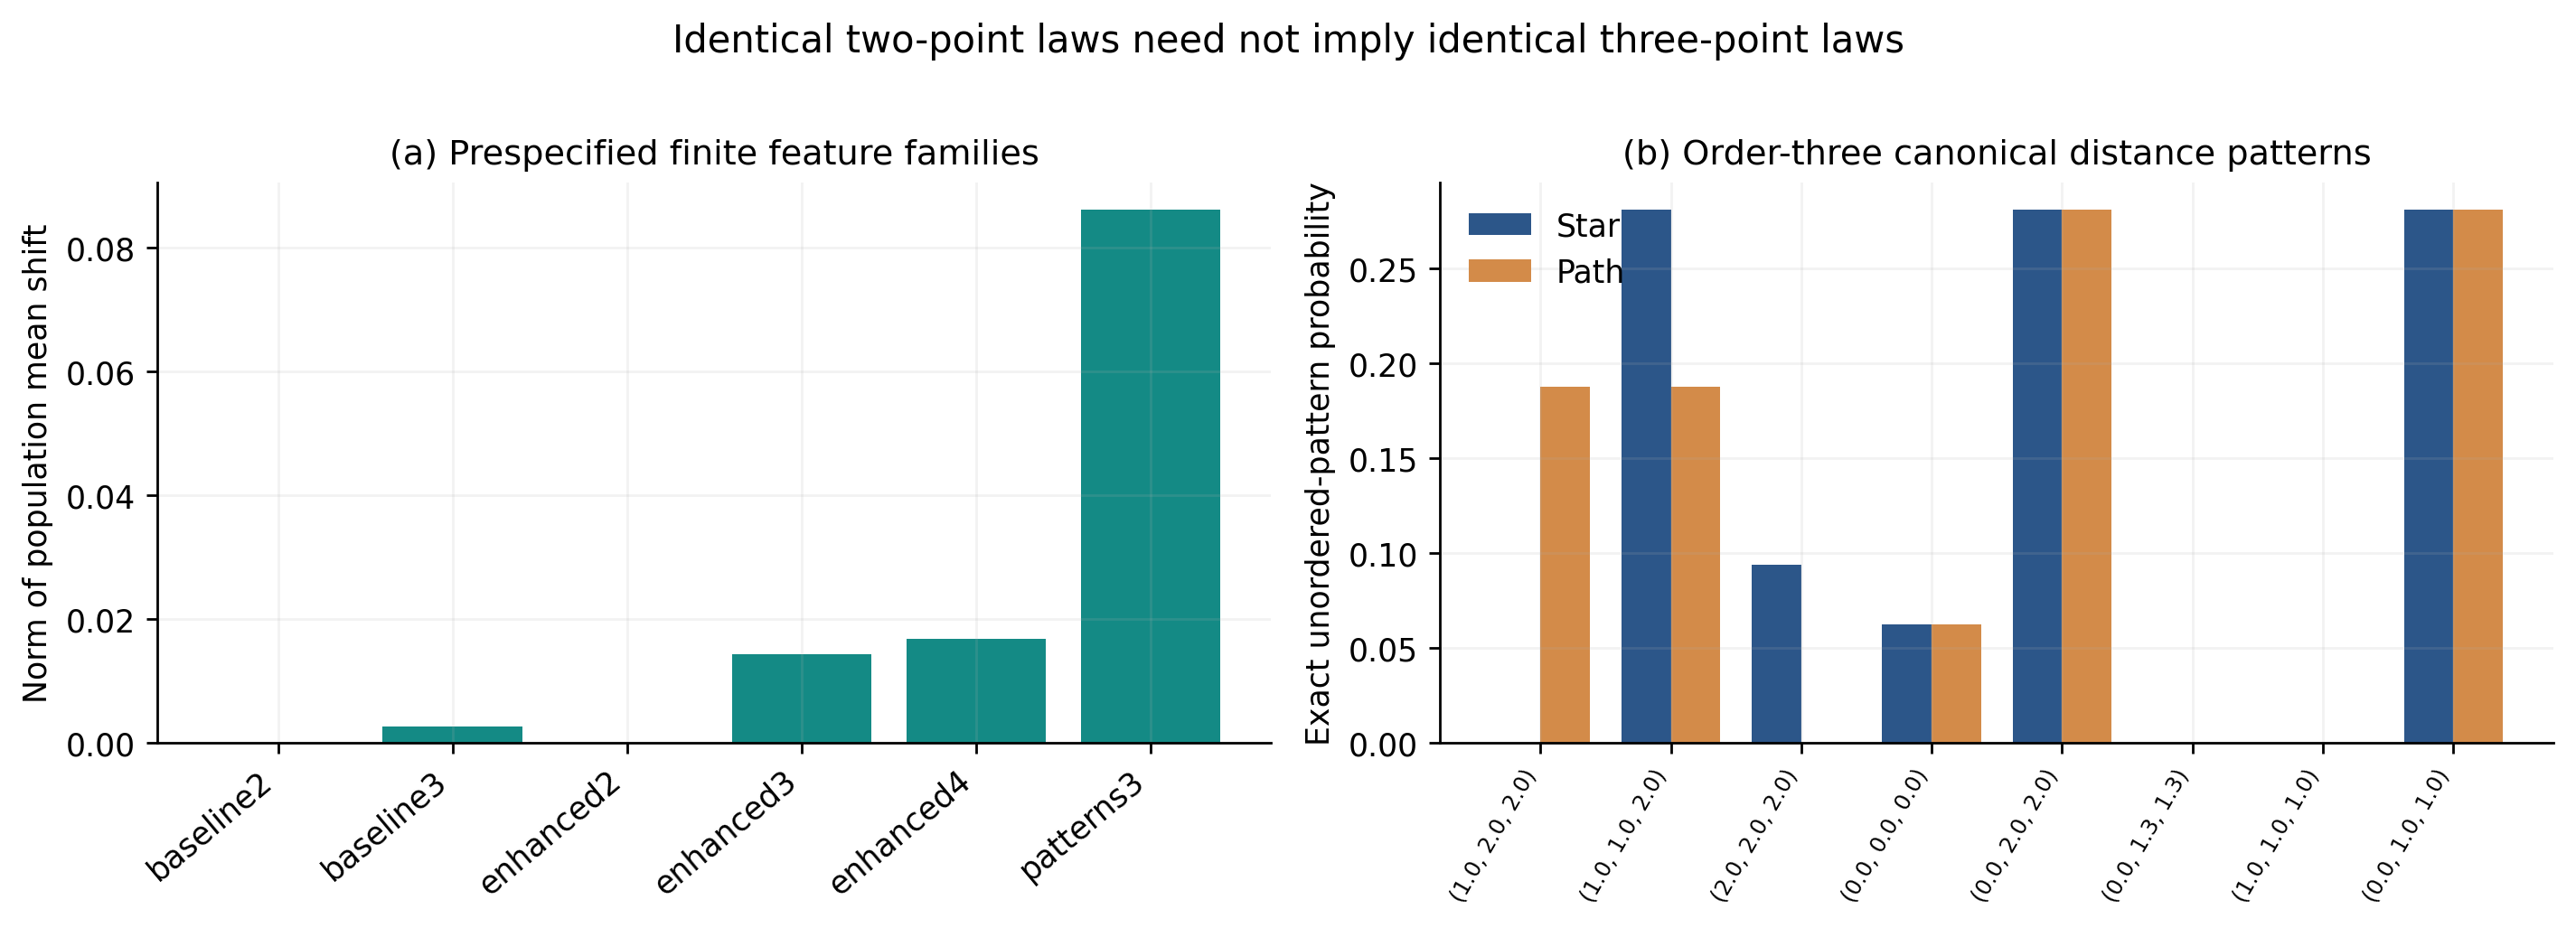

fig02_size_power_comparison


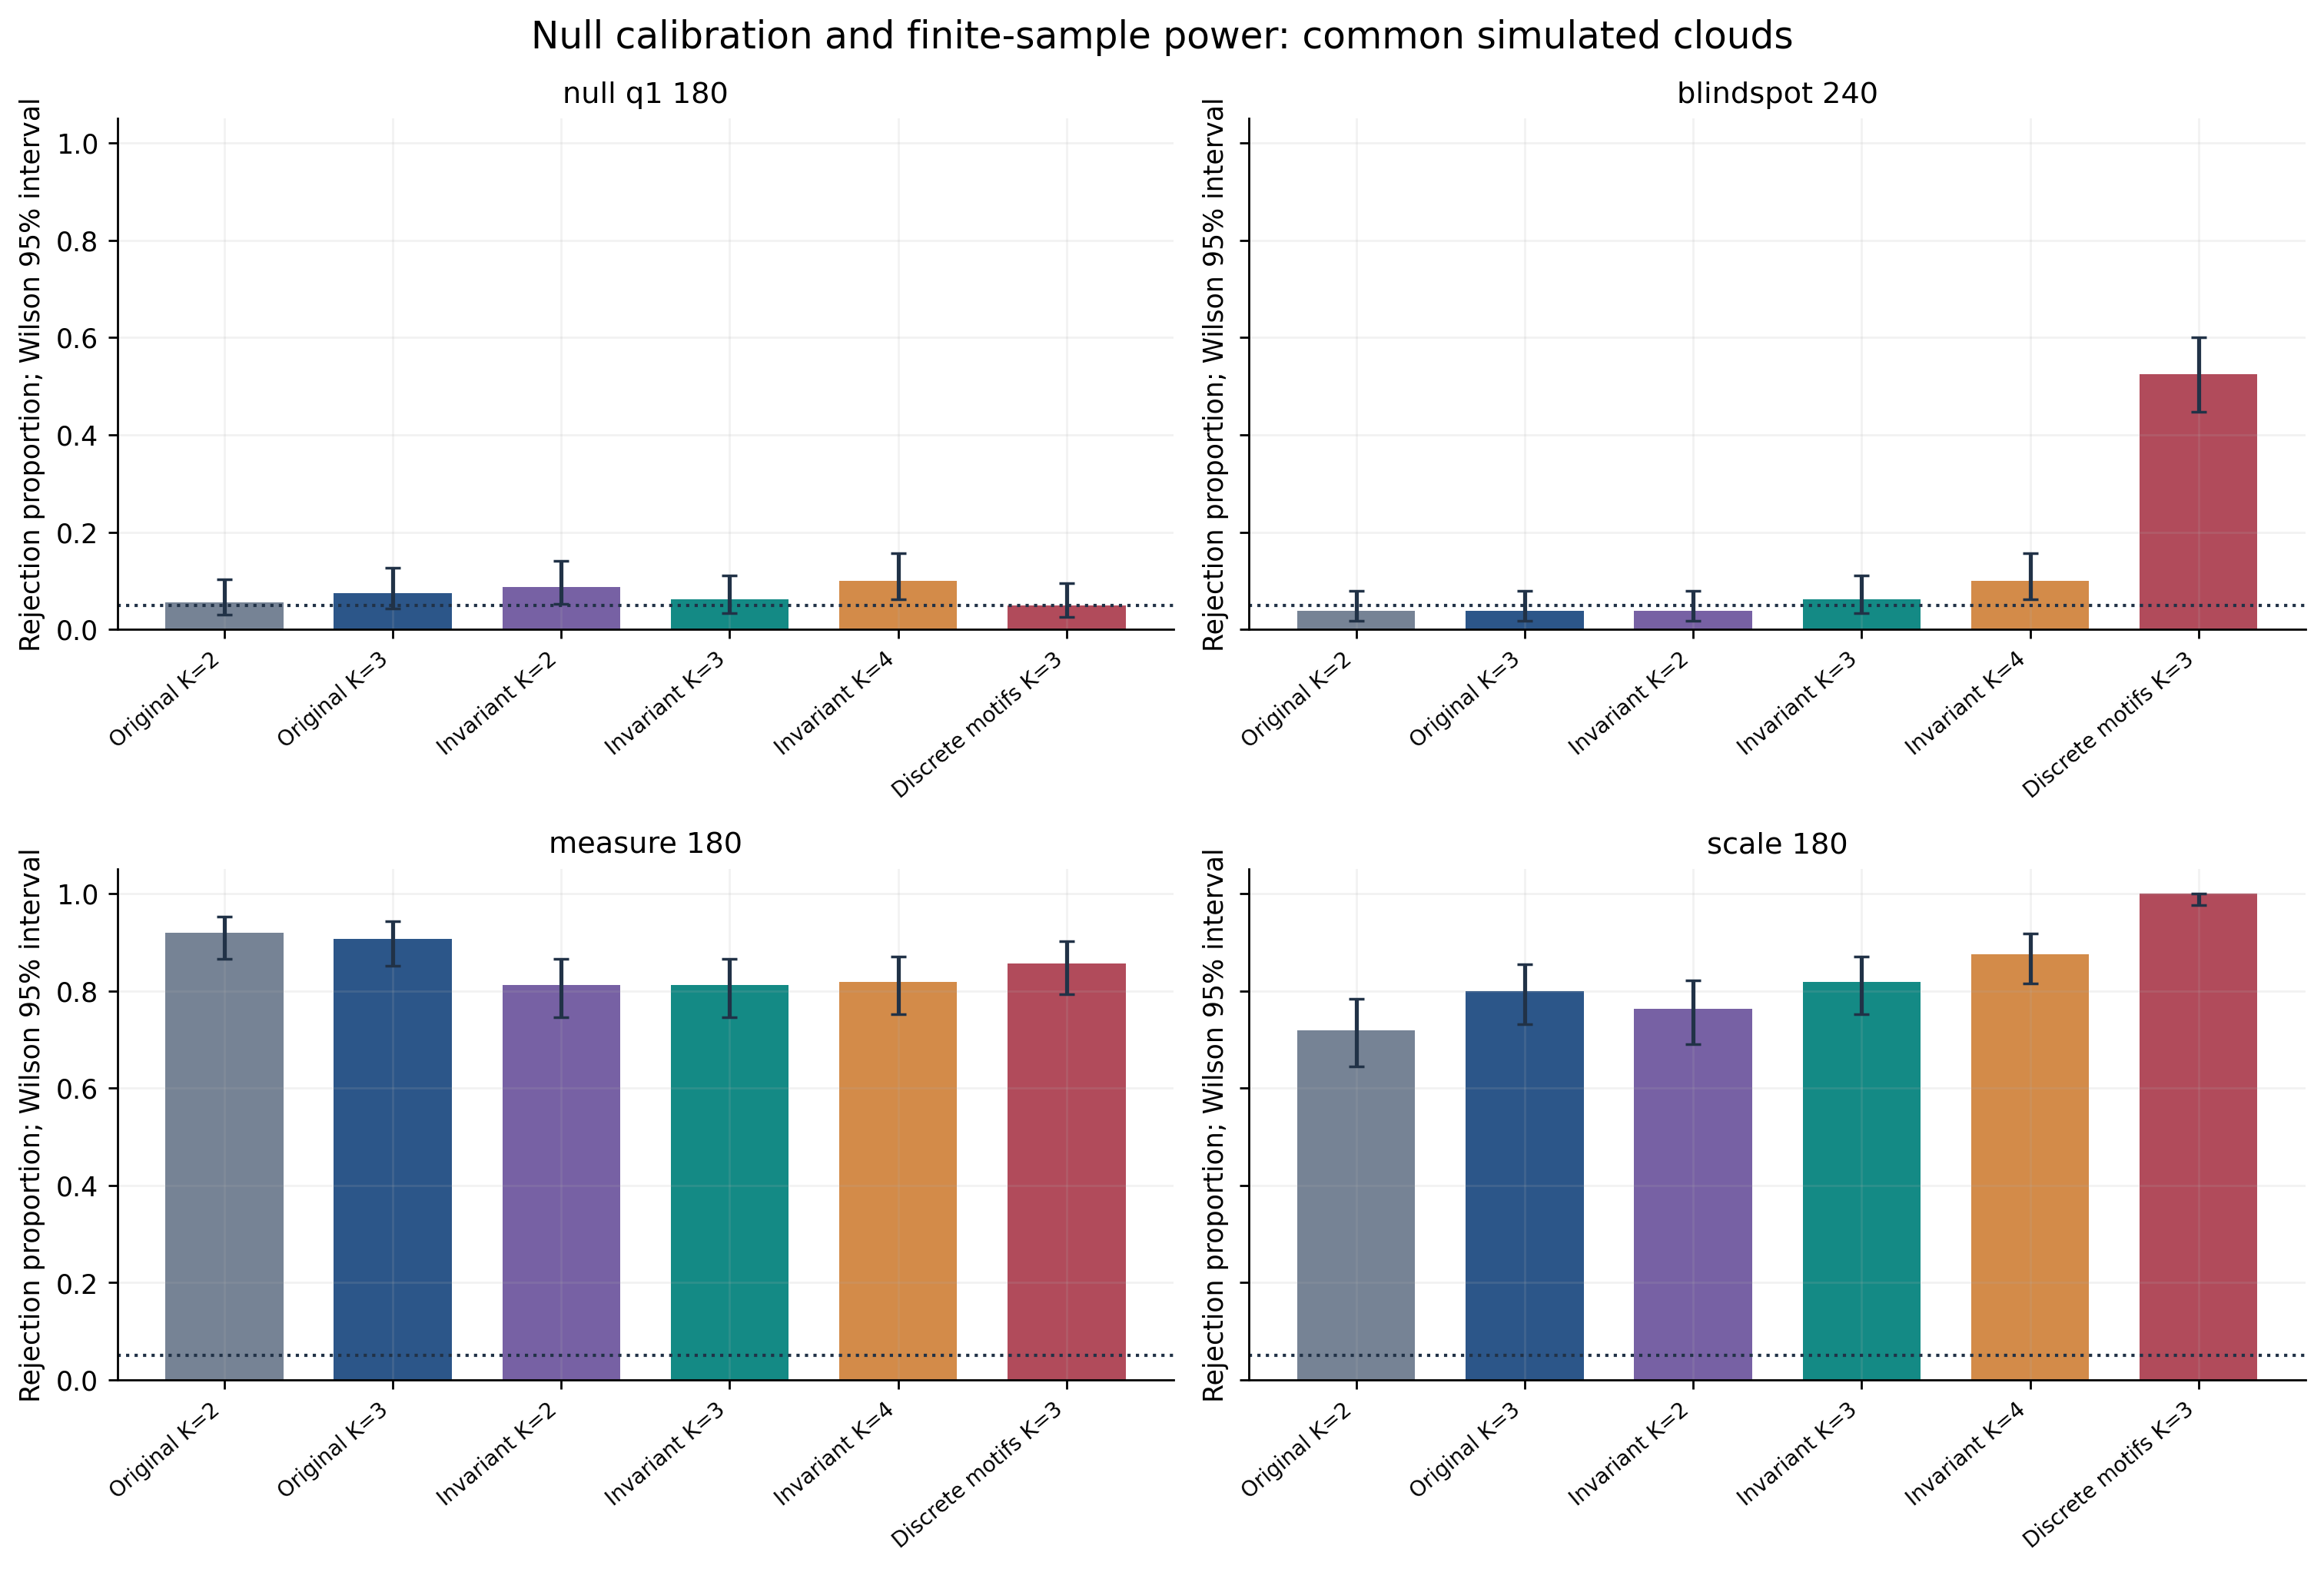

fig03_blindspot_sample_size


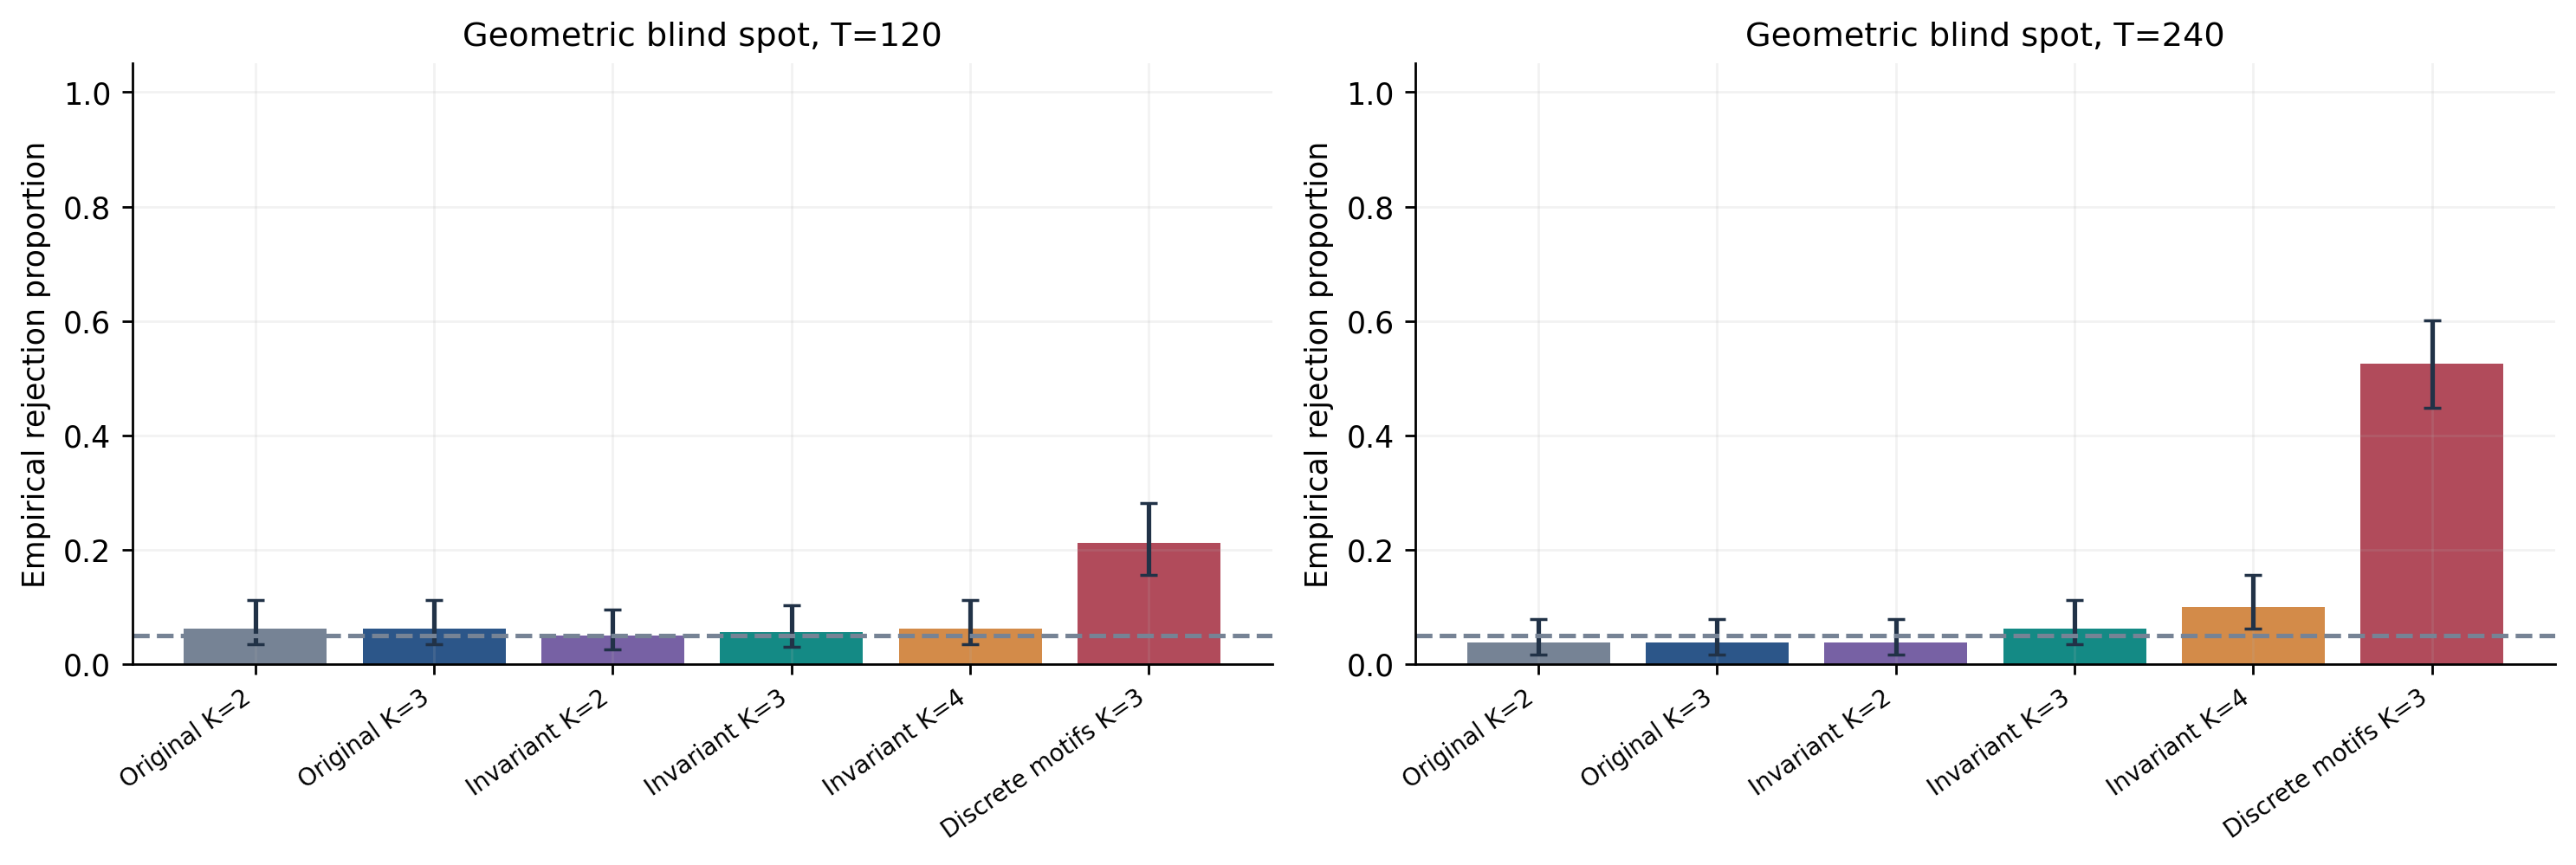

fig06_null_robustness


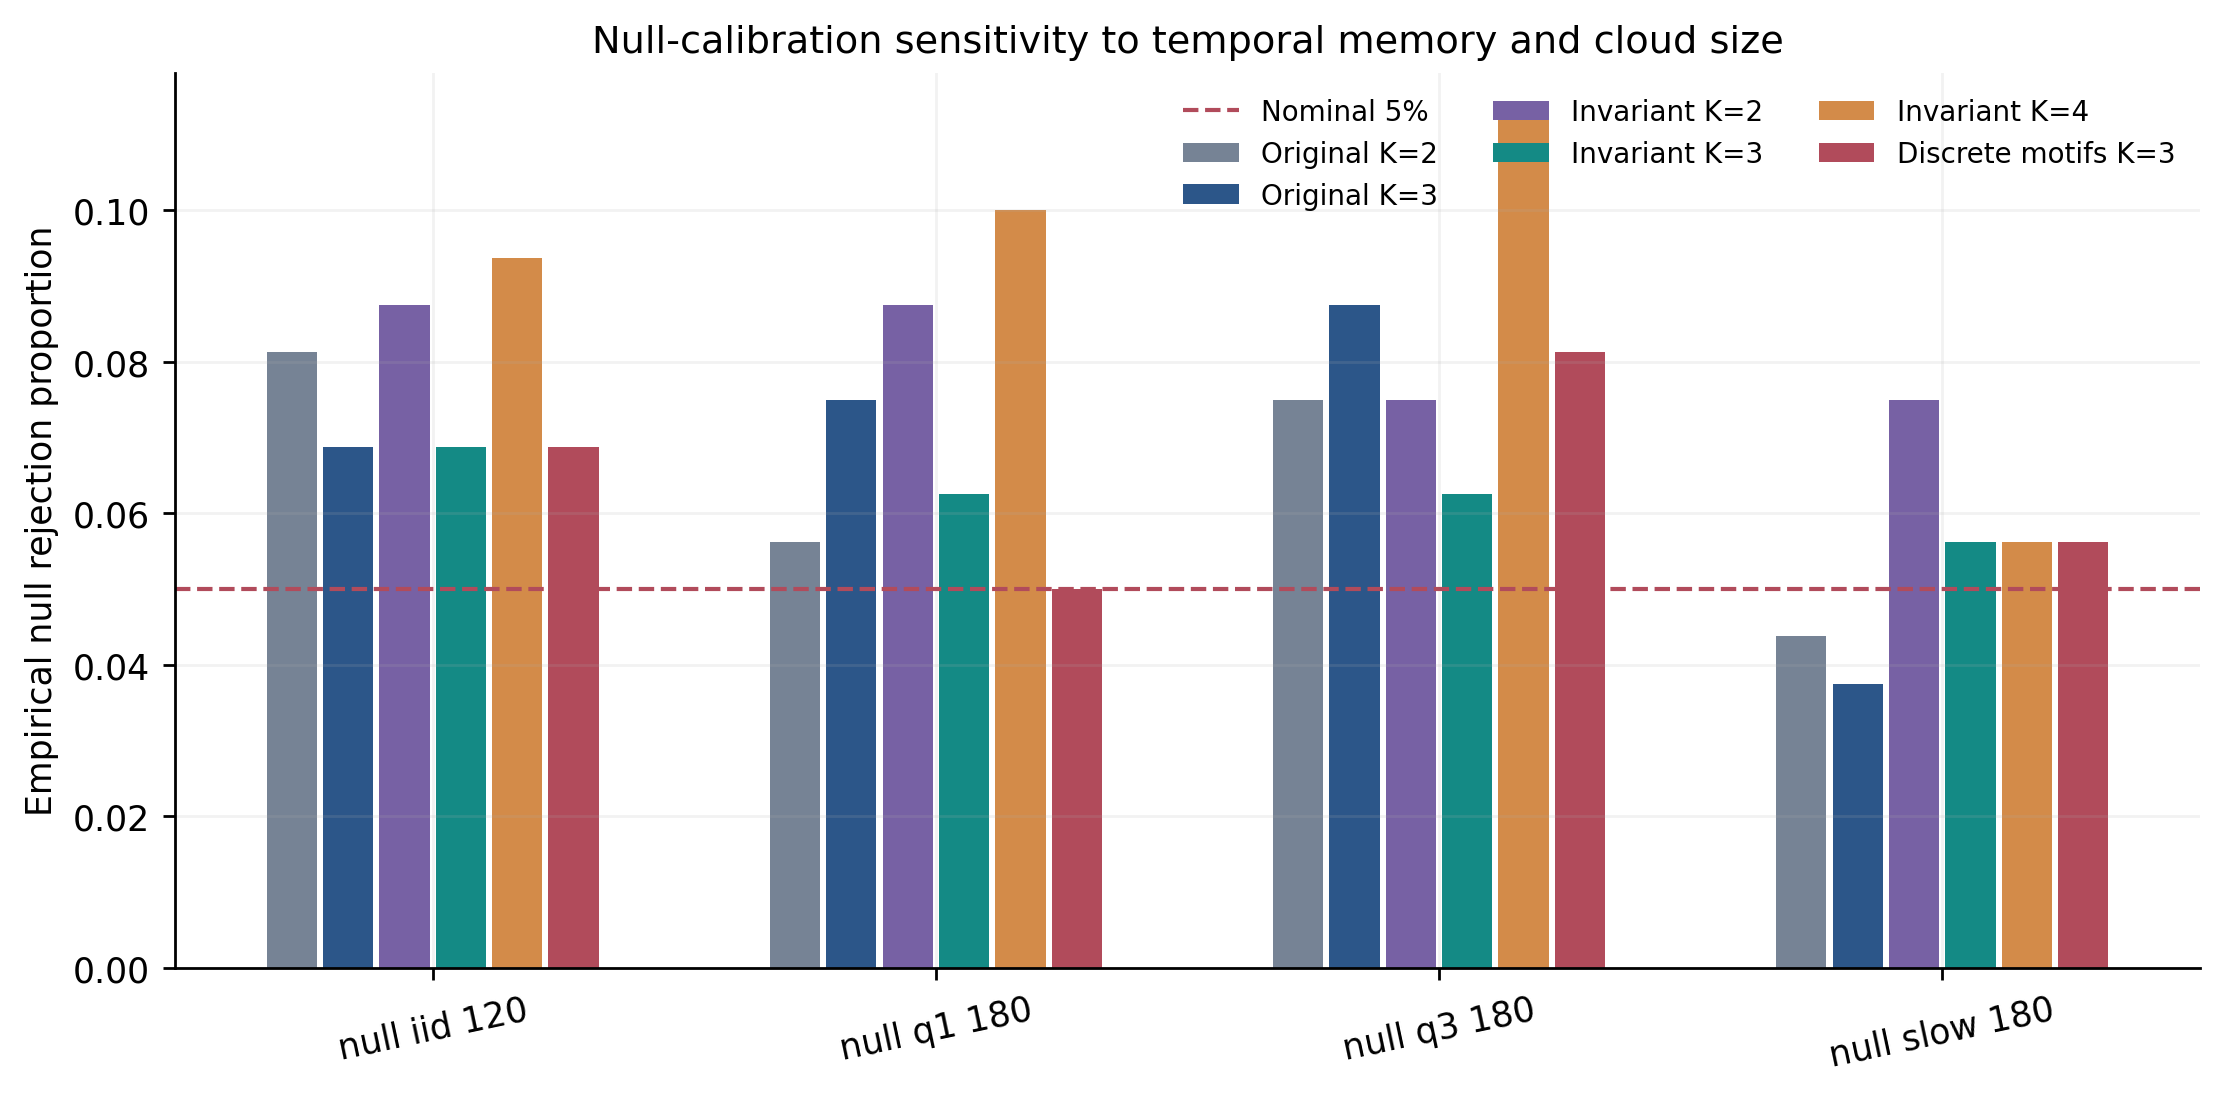

In [4]:
import pandas as pd
from IPython.display import display, Image
summary = pd.read_csv(OUT/'02_monte_carlo'/'summary_rates.csv',keep_default_na=False)
cols=['setup','method','n_valid','rejection_rate','wilson_low','wilson_high','median_cp_abs_error']
display(summary[cols].sort_values(['setup','method']).reset_index(drop=True))
for fig in ['fig01_exact_signal_and_motifs','fig02_size_power_comparison','fig03_blindspot_sample_size','fig06_null_robustness']:
    folder = '01_exact' if fig.startswith('fig01') else '03_figures'
    path=OUT/folder/(fig+'.png')
    if path.exists():
        print(fig)
        display(Image(filename=str(path),width=950))


## 5. Verify and download the comprehensive results ZIP

The ZIP includes all raw and summarized outputs, export-ready plots, tables, and audit files. If your runtime is interrupted, re-execute the notebook with the same configuration and the same persistent output directory.

In [5]:
zip_path=OUT.parent/(OUT.name+'.zip')
assert zip_path.exists() and zip_path.stat().st_size>1000
print('Results ZIP:', zip_path, 'bytes:', zip_path.stat().st_size)
try:
    from google.colab import files
    files.download(str(zip_path))
except ImportError:
    print('Outside Colab: ZIP retained at', zip_path)


Results ZIP: /content/annealed_gromov_fast_results.zip bytes: 1741416


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>